In [19]:
import pandas as pd
import matplotlib.pyplot as plt


# Part A — Data Quality & Basic Insights-----------------------------
# Imports and load the raw CSV

# Load the original sales data--------------------------------
sales = pd.read_csv("sales_raw.csv")

# Inspect the data
print(sales.head())
print("Dataset shape:", sales.shape)
print("Column names:", sales.columns.tolist())
print("\nData types:")
print(sales.dtypes)

print("\nMissing values:")
print(sales.isna().sum())

print("\nDuplicate rows:")
display(sales.duplicated().sum())

   transaction_id  sale_date region    category  quantity unit_price
0            1001  10/1/2026  North       food        2.0        120
1            1002  10/1/2026  South       Books       1.0        250
2            1003  10/2/2026  North        Food       3.0        110
3            1004  10/2/2026   East  Stationery       4.0         50
4            1005  10/3/2026  SOUTH       books       2.0        250
Dataset shape: (21, 6)
Column names: ['transaction_id', 'sale_date', 'region', 'category', 'quantity', 'unit_price']

Data types:
transaction_id      int64
sale_date             str
region                str
category              str
quantity          float64
unit_price            str
dtype: object

Missing values:
transaction_id    0
sale_date         0
region            1
category          0
quantity          1
unit_price        1
dtype: int64

Duplicate rows:


np.int64(1)

In [20]:
# ---------------------------------------Clean the data---------------------------------------
# Keep the original row count for comparison
rows_before = len(sales)

# Remove extra spaces and standardize text
sales["region"] = sales["region"].str.strip().str.title()
sales["category"] = sales["category"].str.strip().str.title()

# Convert quantity and price to numeric values
# Invalid values become NaN
sales["quantity"] = pd.to_numeric(sales["quantity"], errors="coerce")
sales["unit_price"] = pd.to_numeric(sales["unit_price"], errors="coerce")

# Convert sale_date to a date
sales["sale_date"] = pd.to_datetime(sales["sale_date"], errors="coerce")

# Remove duplicate rows
sales = sales.drop_duplicates()

# Remove rows with missing or invalid important values
sales = sales.dropna(
    subset=["sale_date", "region", "category", "quantity", "unit_price"]
)

# Remove rows with zero or negative quantity or price
sales = sales[
    (sales["quantity"] > 0) &
    (sales["unit_price"] > 0)
]

rows_after = len(sales)

print("Rows before cleaning:", rows_before)
print("Rows after cleaning:", rows_after)
print("Rows removed:", rows_before - rows_after)

display(sales.head())

Rows before cleaning: 21
Rows after cleaning: 14
Rows removed: 7


,transaction_id,sale_date,region,category,quantity,unit_price
0,1001,2026-10-01,North,Food,2.0,120.0
1,1002,2026-10-01,South,Books,1.0,250.0
2,1003,2026-10-02,North,Food,3.0,110.0
3,1004,2026-10-02,East,Stationery,4.0,50.0
4,1005,2026-10-03,South,Books,2.0,250.0


Revenue by region:


region
East       740.0
North    11470.0
South     1035.0
West       530.0
Name: revenue, dtype: float64

Revenue by category:


category
Books          1370.0
Food           1945.0
Stationery    10460.0
Name: revenue, dtype: float64

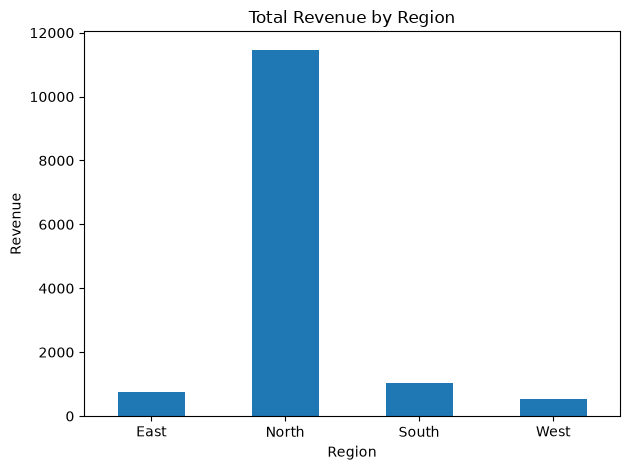

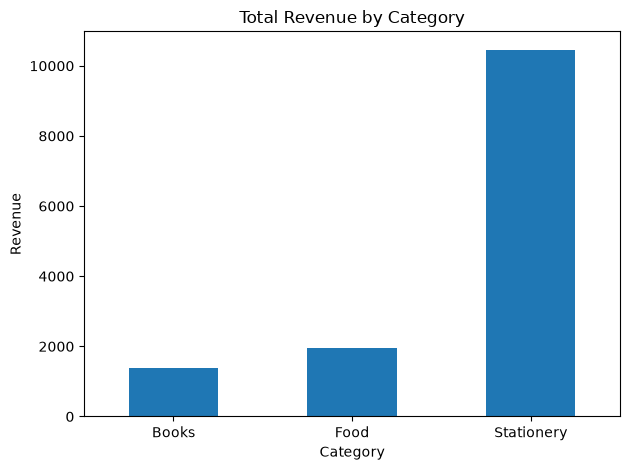

In [ ]:
#--------------------------------Calculate revenue and summarize------------------------------

# Calculate revenue for each transaction
sales["revenue"] = sales["quantity"] * sales["unit_price"]

# Summarize revenue by region
region_summary = sales.groupby("region")["revenue"].sum()
print("Revenue by region:")
display(region_summary)

# Summarize revenue by category
category_summary = sales.groupby("category")["revenue"].sum()
print("Revenue by category:")
display(category_summary)


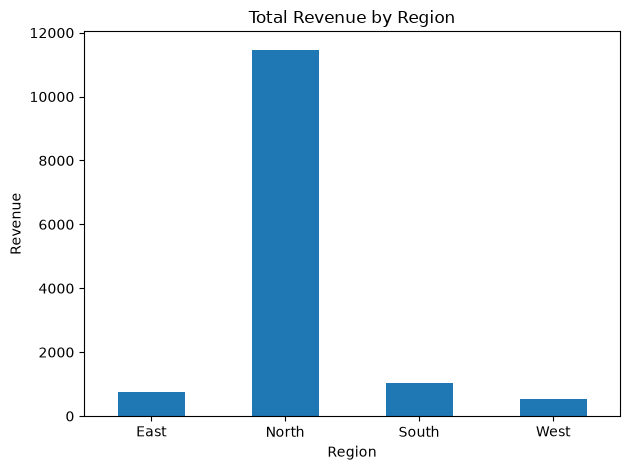

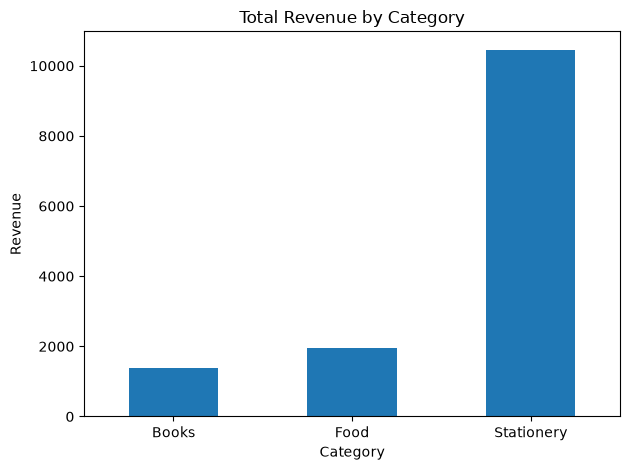

North has the highest revenue: 11470.0
Stationery has the highest revenue: 10460.0
Cleaned data saved to cleaned_sales.csv


In [26]:
#---------------------two labelled charts and two evidence-based findings-----------------------

# Chart 1: Revenue by region
region_summary.plot(kind="bar")

plt.title("Total Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Revenue")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# Chart 2: Revenue by category
category_summary.plot(kind="bar")

plt.title("Total Revenue by Category")
plt.xlabel("Category")
plt.ylabel("Revenue")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Find the region and category with the highest revenue
highest_region = region_summary.idxmax()
highest_region_revenue = region_summary.max()

highest_category = category_summary.idxmax()
highest_category_revenue = category_summary.max()

print(
    highest_region,
    "has the highest revenue:",
    highest_region_revenue
)

print(
    highest_category,
    "has the highest revenue:",
    highest_category_revenue
)

#Save the cleaned CSV
sales.to_csv("cleaned_sales.csv", index=False)

print("Cleaned data saved to cleaned_sales.csv")

In [33]:
#---------------------------------Load cleaned data and add tax------------------------

# Load the cleaned data
updated_sales = pd.read_csv("cleaned_sales.csv")

# Add tax amount equal to 5% of revenue
updated_sales["tax_amount"] = updated_sales["revenue"] * 0.05

# Show the first five rows
display(updated_sales.head())

,transaction_id,sale_date,region,category,quantity,unit_price,revenue,tax_amount
0,1001,2026-10-01,North,Food,2.0,120.0,240.0,12.0
1,1002,2026-10-01,South,Books,1.0,250.0,250.0,12.5
2,1003,2026-10-02,North,Food,3.0,110.0,330.0,16.5
3,1004,2026-10-02,East,Stationery,4.0,50.0,200.0,10.0
4,1005,2026-10-03,South,Books,2.0,250.0,500.0,25.0


In [34]:
#--------------------------------Increase Books prices by 10%-------------------------------

# Increase the unit price of Books by 10%
books_rows = updated_sales["category"] == "Books"

updated_sales.loc[books_rows, "unit_price"] = (
    updated_sales.loc[books_rows, "unit_price"] * 1.10
)

# Recalculate revenue and tax after the price update
updated_sales["revenue"] = (
    updated_sales["quantity"] * updated_sales["unit_price"]
)

updated_sales["tax_amount"] = updated_sales["revenue"] * 0.05

display(updated_sales.head(100))

,transaction_id,sale_date,region,category,quantity,unit_price,revenue,tax_amount
0,1001,2026-10-01,North,Food,2.0,120.0,240.0,12.00
1,1002,2026-10-01,South,Books,1.0,275.0,275.0,13.75
2,1003,2026-10-02,North,Food,3.0,110.0,330.0,16.50
3,1004,2026-10-02,East,Stationery,4.0,50.0,200.0,10.00
4,1005,2026-10-03,South,Books,2.0,275.0,550.0,27.50
5,1007,2026-10-04,North,Stationery,3.0,60.0,180.0,9.00
6,1008,2026-10-04,East,Books,1.0,330.0,330.0,16.50
7,1009,2026-10-05,West,Food,5.0,90.0,450.0,22.50
8,1012,2026-10-06,North,Books,1.0,352.0,352.0,17.60
9,1015,2026-10-08,East,Food,2.0,120.0,240.0,12.00


In [36]:
#------------------------------Remove one selected transaction--------------------------

# Show the selected transaction
display(updated_sales[updated_sales["transaction_id"] == 1019])

# Remove the selected transaction
updated_sales = updated_sales[
    updated_sales["transaction_id"] != 1019
]

print("Transaction 1019 removed.")

,transaction_id,sale_date,region,category,quantity,unit_price,revenue,tax_amount


Transaction 1019 removed.


In [37]:
#-------------------------Add & remove temporary review column------------------------

# Add a temporary column for review
updated_sales["review_status"] = "Reviewed"

# Remove the temporary column
updated_sales = updated_sales.drop(columns=["review_status"])

print("Temporary review_status column removed.")

Temporary review_status column removed.
